<div class="alert alert-info">
<h1>Count Regression</h1>
<h4>Homework Environmental Statistics 2</h4>
<h4>Your Names in Here!</h4>
</div>

This weeks exercises will practice the content of the lecture and tutorials and *extend* them in different ways:
 - step-wise model selection;
 - BIC as criterion of model quality;
 - plot univariate relationship from a multivariate model (“conditional plot”).
 
*Please* try to **switch off** all automatic reporting of model selection steps or package warnings, which both only swamp the PDF you generate without providing useful information.

## Exercise 1 (20 points): Plant species richness on Galapagos islands 
Galapagos is a very remote archipelago. Its unique fauna and flora have attracted biologists, ecologists and evolutionary biologists for hundreds of years. The data set `gala` (in **faraway**) gives the total and endemic number of plant species for each of the 30 islands of Galapagos, along with some geographic information. What are the key drivers of plant species richness? (Hint: The number of species is typically a [power-law function of area](https://en.wikipedia.org/wiki/Species%E2%80%93area_relationship)   *A*: $S = cA^z$. On a log-log-scale, this becomes $\log S = \log c + z \log A$. Using count data, *we automatically log-transform the response*, so we additionally need to use $\log$ area as predictor.) 


  1. Plot the logarithm of the number of plant species against log(area), elevation and distance to nearest island, separately. (**2 points**)
  2. Formulate a GLM for count data (Poisson), using the above three variables as predictors. Add pairwise interactions and, if the plot suggests a non-linear relationship, also quadratic terms. Is this a "good model" (explained deviance, dispersion, number of predictors, etc.)? (**3 points**)
  3. Repeat the same plotting, analysis and critique for the number of endemic plant species. (**2 points**)
  4. Repeat the species richness analysis using a negative binomial GLM. Does that make a difference to (i) model parameters and their errors, (ii) significances, and (iii) dispersion? (**3 points**)
  5. Repeat step 4 for the *endemic* species richness. (**2 points**)
  6. Simplify both negative binomial models automatically, using backwards stepwise model selection with BIC as criterion. (**3 points**)
  7. Plot both data and the models (with 95% confidence intervals) for the effect of log(area); use the untransformed scale for the response. Make the plot size 5 x 5 inches (not the default 4 x 4). (**3 points**)
  8. Interpret the findings, particular the figure from step 7. Pay attention to whether the power-law slopes ("z" in the above equation) are similar or not. (**2 points**)

In [1]:
# Call the necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from sklearn.linear_model import LinearRegression, PoissonRegressor
from sklearn.metrics import mean_squared_error
import pingouin as pg
#import pymc3 as pm
from patsy import dmatrices
import scipy
from mlxtend.feature_selection import SequentialFeatureSelector
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings

# call dataset
gala = pd.read_csv("gala.csv")

# Reset the index by replacing with name
gala = gala.set_index('Name')
gala.describe()


,Species,Endemics,Area,Elevation,Nearest,Scruz,Adjacent
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,85.233333,26.100000,261.708667,368.033333,10.060000,56.976667,261.098333
std,114.633053,27.331111,864.110519,421.604937,14.274636,68.032334,864.518967
min,2.000000,0.000000,0.010000,25.000000,0.200000,0.000000,0.030000
25%,13.000000,7.250000,0.257500,97.750000,0.800000,11.025000,0.520000
50%,42.000000,18.000000,2.590000,192.000000,3.050000,46.650000,2.590000
75%,96.000000,32.250000,59.237500,435.250000,10.025000,81.075000,59.237500
max,444.000000,95.000000,4669.320000,1707.000000,47.400000,290.200000,4669.320000


In [2]:
gala.head(10)

,Species,Endemics,Area,Elevation,Nearest,Scruz,Adjacent
Name,,,,,,,
Baltra,58,23,25.09,346,0.6,0.6,1.84
Bartolome,31,21,1.24,109,0.6,26.3,572.33
Caldwell,3,3,0.21,114,2.8,58.7,0.78
Champion,25,9,0.10,46,1.9,47.4,0.18
Coamano,2,1,0.05,77,1.9,1.9,903.82
Daphne.Major,18,11,0.34,119,8.0,8.0,1.84
Daphne.Minor,24,0,0.08,93,6.0,12.0,0.34
Darwin,10,7,2.33,168,34.1,290.2,2.85
Eden,8,4,0.03,71,0.4,0.4,17.95


### 1.1  Plotting


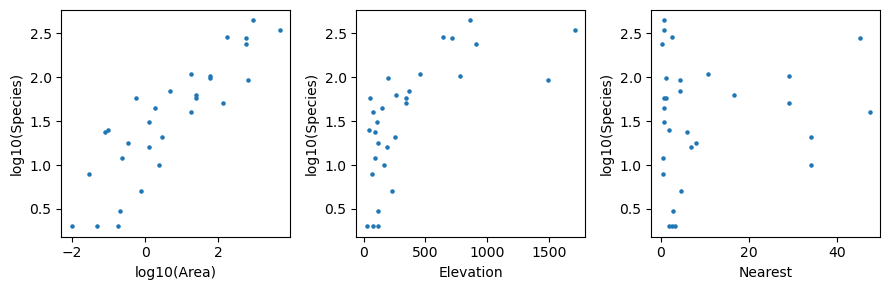

In [3]:
# The plot

# Set up subplots
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

# First subplot
axes[0].scatter(np.log10(gala['Area']), np.log10(gala['Species']), s=5)
axes[0].set_xlabel('log10(Area)')
axes[0].set_ylabel('log10(Species)')

# Second subplot
axes[1].scatter(gala['Elevation'], np.log10(gala['Species']), s=5)
axes[1].set_xlabel('Elevation')
axes[1].set_ylabel('log10(Species)')

# Third subplot
axes[2].scatter(gala['Nearest'], np.log10(gala['Species']), s=5)
axes[2].set_xlabel('Nearest')
axes[2].set_ylabel('log10(Species)')

# Adjust layout
plt.tight_layout()

# Show the plots
plt.show()


### 1.2 Analysis

In [4]:
# Define the formula
formula = "Species ~ (np.log(Area) + Elevation + Nearest)**2 + I(Area**2) + I(Elevation**2) + I(Nearest**2)"

# Fit the GLM
fp = sm.GLM.from_formula(formula, family=sm.families.Poisson(), data=gala).fit()

# Print the summary
print(fp.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                Species   No. Observations:                   30
Model:                            GLM   Df Residuals:                       20
Model Family:                 Poisson   Df Model:                            9
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -217.59
Date:                Fri, 31 Oct 2025   Deviance:                       274.34
Time:                        12:11:57   Pearson chi2:                     274.
No. Iterations:                     6   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  3

In [5]:
# Extract the null deviance
null_deviance = fp.null_deviance

# Extract the residual deviance
residual_deviance = fp.deviance

# Calculate R-squared
r_squared = 1 - (residual_deviance / null_deviance)


print('The null deviance is :', null_deviance)
print('The residual deviance is :', residual_deviance)
print("R-squared is:", r_squared)

The null deviance is : 3510.728616400754
The residual deviance is : 274.3403502246894
R-squared is: 0.9218565773090297


The model results suggest that the Poisson distribution is unsuitable, as the residuals are substantially overdispersed (274/20 ≫ 1). Also, for 30 data points this model with 9 parameters (plus intercept) is overkill and should be reduced to 3 or so. Finally, the fit of the model is excellent, explaining a lot (1 − 274/3510 = 0.92) of the deviance in the data.

### 1.3 Endemics

C:\Users\Ikedichi_Azuh\anaconda3\envs\envstats2\Lib\site-packages\pandas\core\arraylike.py:396: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


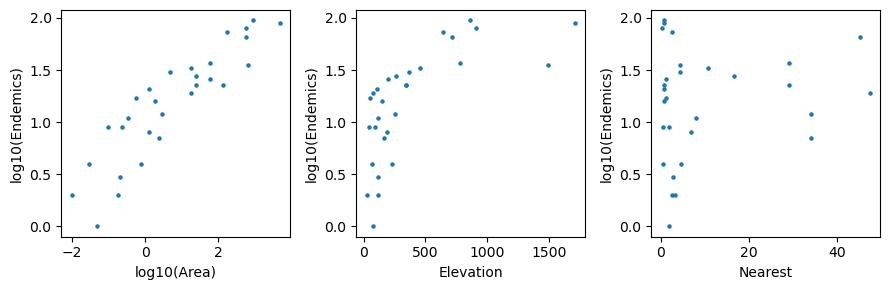

In [6]:
# The plot

# Set up subplots
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

# First subplot
axes[0].scatter(np.log10(gala['Area']), np.log10(gala['Endemics']), s=5)
axes[0].set_xlabel('log10(Area)')
axes[0].set_ylabel('log10(Endemics)')

# Second subplot
axes[1].scatter(gala['Elevation'], np.log10(gala['Endemics']), s=5)
axes[1].set_xlabel('Elevation')
axes[1].set_ylabel('log10(Endemics)')

# Third subplot
axes[2].scatter(gala['Nearest'], np.log10(gala['Endemics']), s=5)
axes[2].set_xlabel('Nearest')
axes[2].set_ylabel('log10(Endemics)')

# Adjust layout
plt.tight_layout()

# Show the plots
plt.show()


In [7]:
# Define the formula
formula = "Endemics ~ (np.log(Area) + Elevation + Nearest)**2 + I(Area**2) + I(Elevation**2) + I(Nearest**2)"

# Fit the GLM
fpe = sm.GLM.from_formula(formula, family=sm.families.Poisson(), data=gala).fit()

# Print the summary
print(fpe.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:               Endemics   No. Observations:                   30
Model:                            GLM   Df Residuals:                       20
Model Family:                 Poisson   Df Model:                            9
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -99.410
Date:                Fri, 31 Oct 2025   Deviance:                       65.869
Time:                        12:12:02   Pearson chi2:                     60.5
No. Iterations:                     5   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  2

The situation for the endemics is similar to all plant species: overdispersed (but only by a factor of 3); overcomplicated, with three non-significant interactions; and explaining about 91% of the deviance.

### 1.4 Negative binomial model for plant species richness

In [205]:
# Fetch the alpha value
gala2 = gala.copy()   # use .copy(), otherwise changes to one will be presnt in both
gala2['lambda_'] = fp.mu

gala2['ols_dep'] = gala2.apply(lambda x: ((x['Species'] - x['lambda_'])**2 - x['lambda_']) / x['lambda_'], axis=1)

ols_expr = """ols_dep ~ lambda_ - 1"""  # do not to use an intercept of regression
    
olsr_results = smf.ols(ols_expr, gala2).fit()
alpha = olsr_results.params.iloc[0]

print('Alpha value to use is: ', np.round(alpha,3) )



Alpha value to use is:  0.034


In [206]:
# Negative binomial

# Define the formula
formula = "Species ~ (np.log(Area) + Elevation + Nearest)**2 + I(Area**2) + I(Elevation**2) + I(Nearest**2)"

# Fit the GLM
fnb = sm.GLM.from_formula(formula, family=sm.families.NegativeBinomial(alpha=0.034), data=gala).fit() 

# Print the summary
print(fnb.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                Species   No. Observations:                   30
Model:                            GLM   Df Residuals:                       20
Model Family:        NegativeBinomial   Df Model:                            9
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -156.47
Date:                Fri, 31 Oct 2025   Deviance:                       121.81
Time:                        16:00:25   Pearson chi2:                     119.
No. Iterations:                     9   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  3

In [10]:
# Extract the null deviance
null_deviance = fnb.null_deviance

# Extract the residual deviance
residual_deviance = fnb.deviance

# Calculate R-squared
r_squared = 1 - (residual_deviance / null_deviance)


print('The null deviance is :', null_deviance)
print('The residual deviance is :', residual_deviance)
print("R-squared is:", r_squared)

The null deviance is : 952.5025060889881
The residual deviance is : 121.81137692450815
R-squared is: 0.8721143764496008


In [11]:
# dispersion 
fnb.deviance/fnb.df_resid


6.090568846225407

This model is very different to the Poisson analysis. But still overdispersed (121.81/20=6.1). Both parameter estimates and their standard errors are different to the Poisson model.

### 1.5 Negative binomial model for endemic plant species richness

In [207]:
# fetch alpha
gala2['lambda_2'] = fpe.mu

gala2['ols_dep'] = gala2.apply(lambda x: ((x['Endemics'] - x['lambda_2'])**2 - x['lambda_2']) / x['lambda_2'], axis=1)

ols_expr = """ols_dep ~ lambda_2 - 1"""  # do not to use an intercept of regression
    
olsr_results = smf.ols(ols_expr, gala2).fit()
alpha = olsr_results.params.iloc[0]
print('Alpha value to use is: ', np.round(alpha,3) )



Alpha value to use is:  0.003


In [208]:
# Negative binomial

# Define the formula
formula = "Endemics ~ (np.log(Area) + Elevation + Nearest)**2 + I(Area**2) + I(Elevation**2) + I(Nearest**2)"

# Fit the GLM
fnbe = sm.GLM.from_formula(formula, family=sm.families.NegativeBinomial(alpha=0.003), data=gala).fit()#alpha=0.05

# Print the summary
print(fnbe.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:               Endemics   No. Observations:                   30
Model:                            GLM   Df Residuals:                       20
Model Family:        NegativeBinomial   Df Model:                            9
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -99.232
Date:                Fri, 31 Oct 2025   Deviance:                       63.329
Time:                        16:01:55   Pearson chi2:                     57.8
No. Iterations:                     6   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  2

In [14]:
# Extract the null deviance
null_deviance = fnbe.null_deviance

# Extract the residual deviance
residual_deviance = fnbe.deviance

# Calculate R-squared
r_squared = 1 - (residual_deviance / null_deviance)


print('The null deviance is :', null_deviance)
print('The residual deviance is :', residual_deviance)
print("R-squared is:", r_squared)


The null deviance is : 685.1012070253863
The residual deviance is : 63.328626341102485
R-squared is: 0.9075631079150093


In [209]:
# dispersion 
fnbe.deviance/fnbe.df_resid


3.166431317055124

Like for all plant species, this model is very different to the Poisson analysis. Only the interaction effects are not significant, but still overdispersed (63.3/20=3.2). Both parameter estimates and their standard errors are different to the Poisson model.

### 1.6 Simplify models

In [190]:
# To ignore all warnings
warnings.filterwarnings('ignore')

gala3 = gala.copy()
gala3['np.log(Area)'] = np.log(gala['Area'])
gala3['np.log(Area):Elevation'] = np.log(gala['Area'])*gala['Elevation'] 
gala3['np.log(Area):Nearest'] = np.log(gala['Area'])*gala['Nearest']
gala3['Elevation:Nearest'] = gala['Elevation']*gala['Nearest']
gala3['I(Area ** 2)'] = gala['Area']**2
gala3['I(Elevation ** 2)'] = gala['Elevation']**2
gala3['I(Nearest ** 2)'] = gala['Nearest']**2

# Sequential Backward Selection
sbs = SequentialFeatureSelector(PoissonRegressor(), 
          k_features= (1,10), # "best"
          forward=True, 
          floating=False, 
          scoring='neg_mean_squared_error',
          cv=5
             )
sbs = sbs.fit(gala3.drop(columns=['Species', 'Endemics']), gala3['Species'])

print('\nSequential Forward Selection (k=best):')
print(sbs.k_feature_idx_)
print('CV Score:')
print(sbs.k_score_)




Sequential Forward Selection (k=best):
(3, 5)
CV Score:
-5767.319826602978


In [191]:
pd.DataFrame.from_dict(sbs.get_metric_dict()).T


,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
1,"(5,)","[-148.70249088670397, -4489.7386273188495, -11...",-6172.574105,"(np.log(Area),)",6797.574922,5288.744227,2644.372114
2,"(3, 5)","[-618.0449382743767, -2264.685556940648, -1413...",-5767.319827,"(Scruz, np.log(Area))",6701.030746,5213.629578,2606.814789
3,"(2, 3, 5)","[-599.0298217127619, -2395.7032081742286, -114...",-6225.258128,"(Nearest, Scruz, np.log(Area))",5461.353915,4249.118887,2124.559444
4,"(2, 3, 5, 7)","[-677.222297125802, -4848.8867300910315, -1306...",-7950.501711,"(Nearest, Scruz, np.log(Area), np.log(Area):Ne...",5822.870749,4530.391267,2265.195633
5,"(2, 3, 5, 7, 11)","[-780.0763208185303, -4952.543402777773, -1430...",-12150.908938,"(Nearest, Scruz, np.log(Area), np.log(Area):Ne...",13977.690255,10875.117891,5437.558945
6,"(2, 3, 5, 7, 8, 11)","[-6443.805555555555, -4952.543402777773, -1430...",-12455.487997,"(Nearest, Scruz, np.log(Area), np.log(Area):Ne...",13353.77608,10389.691466,5194.845733
7,"(0, 2, 3, 5, 7, 8, 11)","[-6443.805555555555, -4952.543402777773, -1430...",-14068.303472,"(Area, Nearest, Scruz, np.log(Area), np.log(Ar...",12390.767581,9640.438137,4820.219068
8,"(0, 1, 2, 3, 5, 7, 8, 11)","[-6443.805555555555, -4952.543402777773, -1430...",-14068.303472,"(Area, Elevation, Nearest, Scruz, np.log(Area)...",12390.767581,9640.438137,4820.219068
9,"(0, 1, 2, 3, 5, 7, 8, 9, 11)","[-6443.805555555555, -4952.543402777773, -1430...",-14068.303472,"(Area, Elevation, Nearest, Scruz, np.log(Area)...",12390.767581,9640.438137,4820.219068
10,"(0, 1, 2, 3, 5, 7, 8, 9, 10, 11)","[-6443.805555555555, -4952.543402777773, -1430...",-14068.303472,"(Area, Elevation, Nearest, Scruz, np.log(Area)...",12390.767581,9640.438137,4820.219068


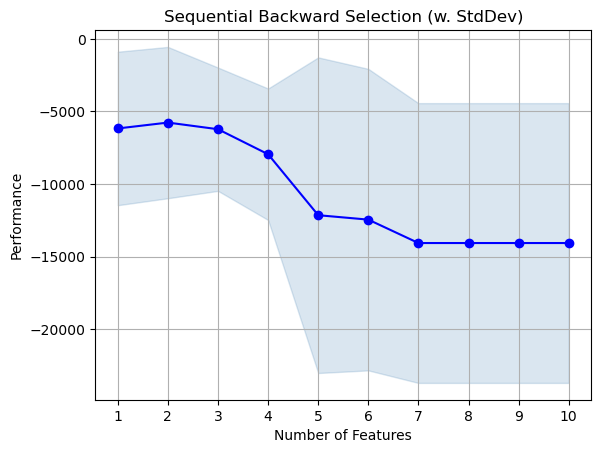

In [192]:
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs

fig1 = plot_sfs(sbs.get_metric_dict(), kind='std_dev')

plt.title('Sequential Backward Selection (w. StdDev)')
plt.grid()
plt.show()

In [176]:
## Model for Species

selector = SequentialFeatureSelector(PoissonRegressor(), #LinearRegression(), PoissonRegressor()
                                     k_features="parsimonious", # If "parsimonious", the smallest feature subset that is within one standard error of the cross-validation performance will be selected
                                     forward=True,
                                     floating=False,
                                     scoring ='neg_mean_squared_error', # 'neg_mean_squared_error', 'r2', "neg_mean_absolute_error", neg_mean_gamma_deviance
                                    )

selector = selector.fit(gala3.drop(columns=['Species', 'Endemics']), gala3['Species'])

# Get the selected features
selected_features = list(selector.k_feature_names_)
print('Sequential Forward Selection: ',selector.k_feature_idx_)
print('With neg_mean_squared_error score: ', selector.k_score_)

# Create the formula with the selected features
sel_formula = f"Species ~ {' + '.join(selected_features)}"

# Fit the negative binomial regression model with selected features, but first get alpha from Poisson
poistep = sm.GLM.from_formula(sel_formula, family=sm.families.Poisson(), data=gala3).fit()
gala4 = gala3.copy() 
gala4['lambda_'] = poistep.mu
gala4['ols_dep'] = gala4.apply(lambda x: ((x['Species'] - x['lambda_'])**2 - x['lambda_']) / x['lambda_'], axis=1)
ols_expr = """ols_dep ~ lambda_ - 1"""  
    
olsr_results2 = smf.ols(ols_expr, gala4).fit()
alpha = olsr_results2.params.iloc[0]
print('==========================================================================')
print('Alpha value to use is: ',alpha)
print('==========================================================================')

fnbstep = sm.GLM.from_formula(sel_formula, family=sm.families.NegativeBinomial(alpha=alpha), data=gala3).fit()
print(fnbstep.summary())


Sequential Forward Selection:  (5,)
With neg_mean_squared_error score:  -6172.574104908698
Alpha value to use is:  0.1863507545679097
                 Generalized Linear Model Regression Results                  
Dep. Variable:                Species   No. Observations:                   30
Model:                            GLM   Df Residuals:                       28
Model Family:        NegativeBinomial   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -142.72
Date:                Fri, 31 Oct 2025   Deviance:                       59.770
Time:                        15:42:14   Pearson chi2:                     56.6
No. Iterations:                     6   Pseudo R-squ. (CS):             0.9985
Covariance Type:            nonrobust                                         
                   coef    std err          z      P>|z|      [0.025      0.

In [177]:
# can also extract the optimal alpha from the negbin model and refit

fneg = smf.negativebinomial(sel_formula, data=gala3).fit()
alpha2 = fneg.params['alpha']

fnbstep2 = sm.GLM.from_formula(sel_formula, family=sm.families.NegativeBinomial(alpha=alpha2), data=gala3).fit()

print('')
print('==========================================================================')
print('The Optimal alpha value to use is: ',alpha2)
print('==========================================================================')
print('')
print(fnbstep2.summary())


Optimization terminated successfully.
         Current function value: 4.629535
         Iterations: 8
         Function evaluations: 10
         Gradient evaluations: 10

The Optimal alpha value to use is:  0.3947354774775609

                 Generalized Linear Model Regression Results                  
Dep. Variable:                Species   No. Observations:                   30
Model:                            GLM   Df Residuals:                       28
Model Family:        NegativeBinomial   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -138.89
Date:                Fri, 31 Oct 2025   Deviance:                       32.604
Time:                        15:42:43   Pearson chi2:                     30.1
No. Iterations:                     6   Pseudo R-squ. (CS):             0.9613
Covariance Type:            nonrobust                        

In [180]:
# r square for fnbstep
1 - (fnbstep.deviance / fnbstep.null_deviance)

0.7659325388911826

In [179]:
# r square for fnbstep2
1 - (fnbstep2.deviance / fnbstep2.null_deviance)

0.7495127144185213

In [147]:
# dispersion 1
fnbstep.deviance/fnbstep.df_resid

2.134637931733665

In [182]:
# dispersion 2
fnbstep2.deviance/fnbstep2.df_resid

1.1644195688309469

Model is compact now and not much overdispersed.

In [188]:
## Model for Endemics

# To ignore all warnings
warnings.filterwarnings('ignore')

selector = SequentialFeatureSelector(PoissonRegressor(), #LinearRegression(), PoissonRegressor()
                                     k_features=1, #'best'
                                     forward=True,
                                     floating=False,
                                     scoring ='neg_mean_squared_error',
                                     )  
selector = selector.fit(gala3.drop(columns=['Endemics', 'Species']), gala3['Endemics'])


selected_features = list(selector.k_feature_names_)

print('Sequential Forward Selection for Endemics response are: ', selector.k_feature_idx_)
print('With neg_mean_squared_error score: ', selector.k_score_)

# Create the formula with the selected features
sel_formula = f"Endemics ~ {' + '.join(selected_features)}"

# Fit the negative binomial regression model with selected features and optiomal alpha
fneg_e = smf.negativebinomial(sel_formula, data=gala3).fit()
alpha3 = fneg_e.params['alpha']

fnbestep = sm.GLM.from_formula(sel_formula, family=sm.families.NegativeBinomial(alpha=alpha3), data=gala3).fit()

print('')
print('==========================================================================')
print('The Optimal alpha value to use is: ',alpha3)
print('==========================================================================')
print('')

print(fnbestep.summary())



Sequential Forward Selection for Endemics response are:  (5,)
With neg_mean_squared_error score:  -235.1096811368017
Optimization terminated successfully.
         Current function value: 3.447575
         Iterations: 9
         Function evaluations: 14
         Gradient evaluations: 14

The Optimal alpha value to use is:  0.14025258404493612

                 Generalized Linear Model Regression Results                  
Dep. Variable:               Endemics   No. Observations:                   30
Model:                            GLM   Df Residuals:                       28
Model Family:        NegativeBinomial   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -103.43
Date:                Fri, 31 Oct 2025   Deviance:                       36.038
Time:                        15:50:24   Pearson chi2:                     31.0
No. Iterations:       

Same here: model is compact and hardly overdispersed.

### 1.7 Plot data and regression lines with confidence intervals
Note: In python, when are ploting against a log-transformed "X", you have to force the x-axis to be log-scaled by adding `plt.xscale('log')` to the plotting code.

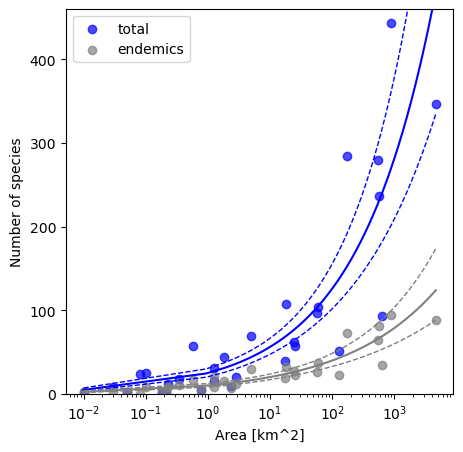

In [189]:
# Create the scatter plot
plt.figure(figsize=(5,5))
plt.scatter(gala['Area'], gala['Species'], c='b', marker='o', label='total', alpha=0.7)

# Add points for 'Endemics'
plt.scatter(gala['Area'], gala['Endemics'], c='grey', marker='o', label='endemics', alpha=0.7)

# Set labels and title
plt.xlabel('Area [km^2]')
plt.ylabel('Number of species')
plt.xscale('log')


newArea_ = np.linspace(min(gala['Area']), max(gala['Area']), num=5000)  # as numpy.ndarray
newNear_ = np.linspace(gala['Nearest'].median(), gala['Nearest'].median(), num=5000)
newScru_ = np.linspace(gala['Scruz'].median(), gala['Scruz'].median(), num=5000)
Area_Near = np.log(newArea_)*newNear_


d = {'np.log(Area)': list(np.log(newArea_)) , 'np.log(Area):Nearest': list(Area_Near),
    'Nearest': list(newNear_), 'Scruz': list(newScru_),'Area': list(newArea_)} # Convert to a dataframe

newdata = pd.DataFrame(data=d)   


predsS = fnbstep.get_prediction(newdata).summary_frame(alpha=0.05) 
predsE = fnbestep.get_prediction(newdata).summary_frame(alpha=0.05) 


plt.plot(newArea_, predsS['mean'], color = "blue") 
plt.plot(newArea_, predsS['mean_ci_lower'], linestyle='dashed', color = "blue", linewidth=1.0)
plt.plot(newArea_, predsS['mean_ci_upper'], linestyle='dashed', color = "blue", linewidth=1.0)

plt.plot(newArea_, predsE['mean'], color = "grey") 
plt.plot(newArea_, predsE['mean_ci_lower'], linestyle='dashed', color = "grey", linewidth=1.0)
plt.plot(newArea_, predsE['mean_ci_upper'], linestyle='dashed', color = "grey", linewidth=1.0)


# Set y-axis limits
plt.ylim(0, 460)

plt.legend()
plt.grid(False)

# Show the plot
plt.show()






## 1.8 Interpretation
For both total species richness, and endemics in particular, island area is the most important predictor. In both cases the number of species follows a power law with indistiguishable exponent of $z=0.35$, but obviously different intercept *c*. (Since endemics are a subset of total species numbers, their intercept *must* be lower.)

The fit to the data is better for endemic species richness, although the data points for the largest island (Isabela) seem to be a poor match.



### **BONUS**
You can also look at `Model-based` and `sequential feature selection` from the `sklearn.feature_selection` module.

In [236]:
from sklearn.feature_selection import SequentialFeatureSelector as SFS

feature_names = gala3.drop(columns=['Species', 'Endemics']).columns
sfs_backward = SFS(PoissonRegressor(), 
                   n_features_to_select='auto', #best 
                   direction="backward")

model = sfs_backward.fit(gala3.drop(columns=['Species', 'Endemics']), gala3['Species'])

selected_features = feature_names[model.get_support()].tolist()
print(f"Features selected by SFS: {selected_features}")

Features selected: ['np.log(Area):Elevation', 'np.log(Area):Nearest', 'Elevation:Nearest', 'I(Area ** 2)', 'I(Elevation ** 2)', 'I(Nearest ** 2)']


In [237]:
# Get the selected features 
from sklearn.feature_selection import SelectFromModel
sfm = SelectFromModel(PoissonRegressor(), max_features=5).fit(gala3.drop(columns=['Species', 'Endemics']), gala3['Species'])

print(f"Features selected by SelectFromModel: {feature_names[sfm.get_support()]}")

Features selected by SelectFromModel: Index(['Area', 'Elevation', 'Nearest', 'Scruz', 'Adjacent'], dtype='object')
